In [ ]:
import pandas as pd
import numpy as np
!pip install tensorflow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten
from sklearn.model_selection import train_test_split

In [99]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()


In [100]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print("X_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape: (10000, 28, 28)
y_test shape: (10000,)


In [101]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (33600, 784)
y_train shape: (60000,)


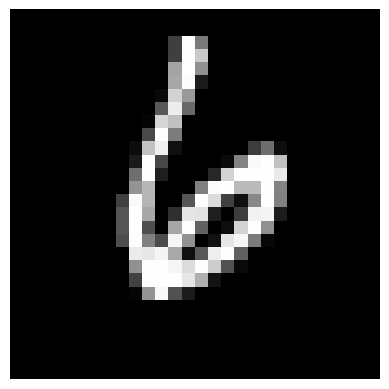

In [102]:
import matplotlib.pyplot as plt

sample_image = X_train[0].reshape(28, 28)

plt.imshow(sample_image, cmap='gray')
plt.axis('off')
plt.show()

In [103]:
model = Sequential()
model.add(Flatten(input_shape=(28, 28)))
model.add(Dense(128, activation='relu'))
model.add(Dense(10, activation='softmax'))
model.summary()

/Users/abhijithk/Documents/data project/ML Project /.venv/lib/python3.13/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [110]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(x_train, y_train, epochs=15, batch_size=32, validation_split=0.2)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9570 - loss: 0.1936 - val_accuracy: 0.9435 - val_loss: 0.3415
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 976us/step - accuracy: 0.9585 - loss: 0.1824 - val_accuracy: 0.9442 - val_loss: 0.3042
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 900us/step - accuracy: 0.9596 - loss: 0.1703 - val_accuracy: 0.9480 - val_loss: 0.2673
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 895us/step - accuracy: 0.9608 - loss: 0.1611 - val_accuracy: 0.9491 - val_loss: 0.2948
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 881us/step - accuracy: 0.9616 - loss: 0.1638 - val_accuracy: 0.9488 - val_loss: 0.3132
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 963us/step - accuracy: 0.9622 - loss: 0.1642 - val_accuracy: 0.9489 - val_loss: 0.3234
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 931us/step - accuracy: 0.9615 - loss: 0.1568 - val_accuracy: 0.9492 - val_loss: 0.3216
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 1s 900us/step - accuracy: 0.9631 - l

In [113]:
y_prob = model.predict(x_test)
y_pred = y_prob.argmax(axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 360us/step


In [114]:
model.predict(x_test).argmax(axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 320us/step


array([7, 2, 1, ..., 4, 5, 6], shape=(10000,))

In [115]:
model.predict(x_test[17].reshape(1,28,28)).argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


array([7])

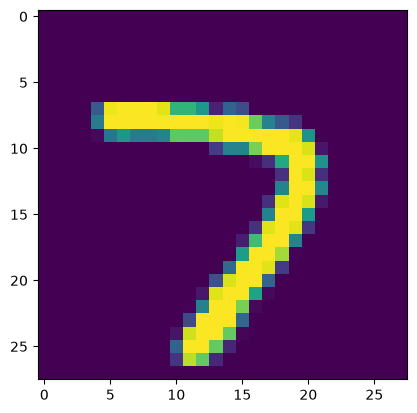

In [116]:
plt.imshow(x_test[17])

In [117]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9486